In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'car.csv', 'car_selling_price_prediction.ipynb', 'venv']


In [4]:
df = pd.read_csv("car.csv")

In [5]:
df.head()


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [6]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


In [7]:
df.duplicated().sum()

np.int64(2)

In [8]:
df = df.drop_duplicates()

In [9]:
df.shape

(299, 9)

In [10]:
df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,299.000000,299.000000,299.000000,299.000000,299.000000
mean,2013.615385,4.589632,7.541037,36916.752508,0.043478
std,2.896868,4.984240,8.567887,39015.170352,0.248720
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.850000,1.200000,15000.000000,0.000000
50%,2014.000000,3.510000,6.100000,32000.000000,0.000000
75%,2016.000000,6.000000,9.840000,48883.500000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [11]:
print("Fuel Type:")
print(df["Fuel_Type"].value_counts())

print("\nSeller Type:")
print(df["Seller_Type"].value_counts())

print("\nTransmission:")
print(df["Transmission"].value_counts())

Fuel Type:
Fuel_Type
Petrol    239
Diesel     58
CNG         2
Name: count, dtype: int64

Seller Type:
Seller_Type
Dealer        193
Individual    106
Name: count, dtype: int64

Transmission:
Transmission
Manual       260
Automatic     39
Name: count, dtype: int64


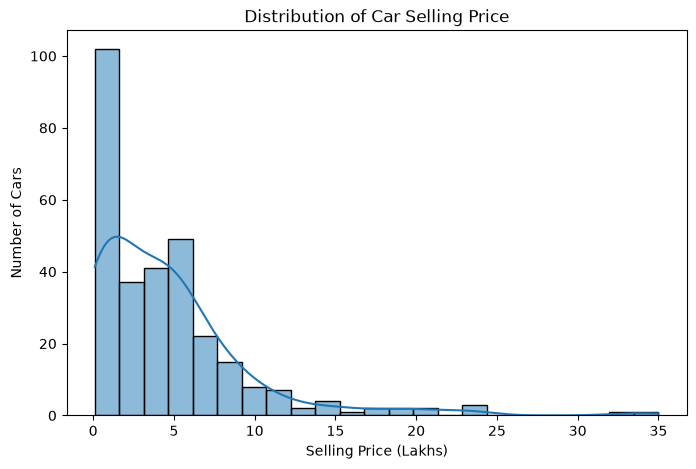

In [12]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Selling_Price"], kde=True)
plt.title("Distribution of Car Selling Price")
plt.xlabel("Selling Price (Lakhs)")
plt.ylabel("Number of Cars")
plt.show()

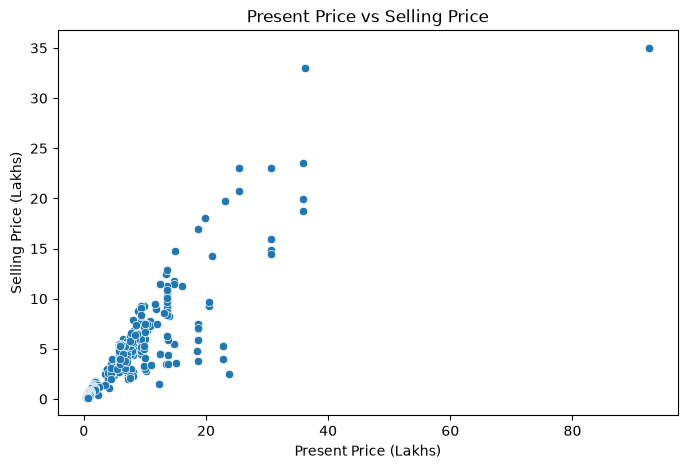

In [13]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Present_Price", y="Selling_Price")
plt.title("Present Price vs Selling Price")
plt.xlabel("Present Price (Lakhs)")
plt.ylabel("Selling Price (Lakhs)")
plt.show()

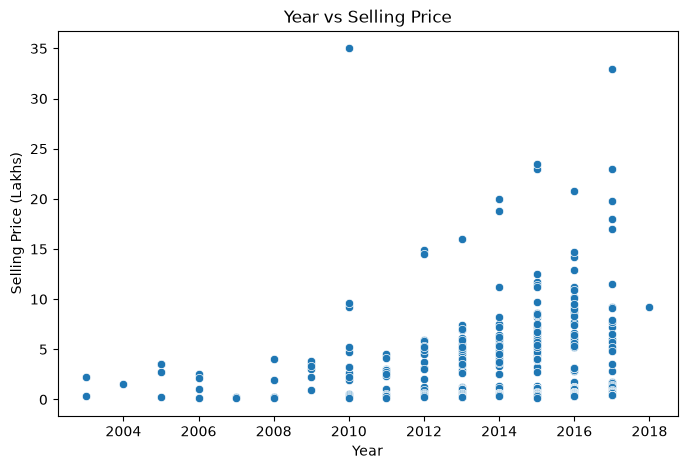

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Year", y="Selling_Price")
plt.title("Year vs Selling Price")
plt.xlabel("Year")
plt.ylabel("Selling Price (Lakhs)")
plt.show()

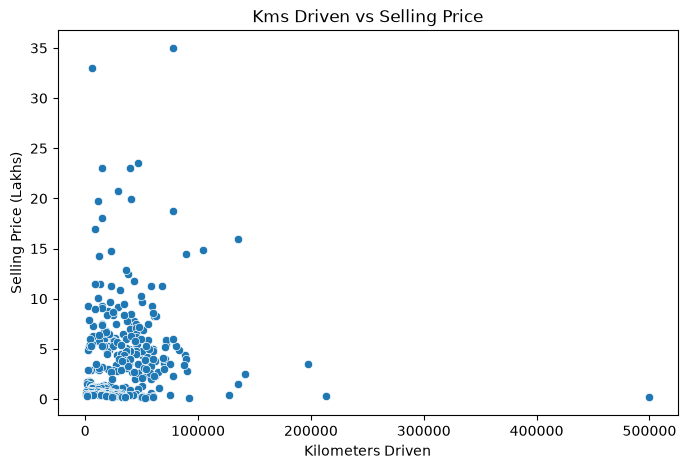

In [15]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Kms_Driven", y="Selling_Price")
plt.title("Kms Driven vs Selling Price")
plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price (Lakhs)")
plt.show()

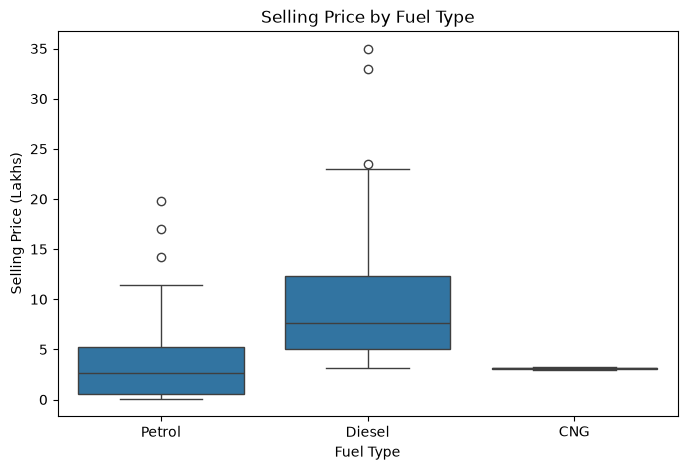

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price")
plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (Lakhs)")
plt.show()

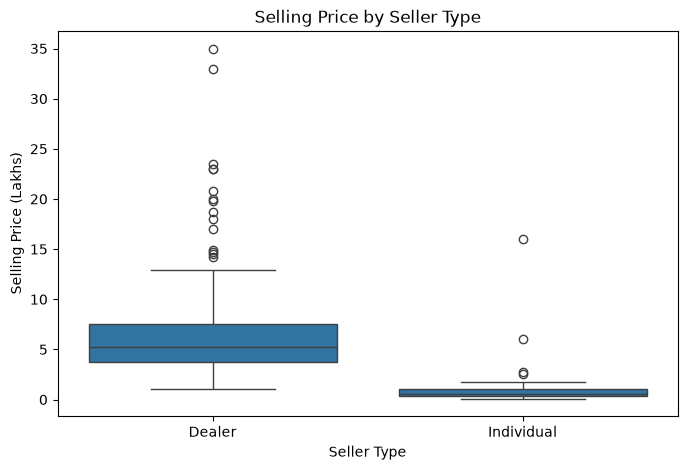

In [17]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Seller_Type", y="Selling_Price")
plt.title("Selling Price by Seller Type")
plt.xlabel("Seller Type")
plt.ylabel("Selling Price (Lakhs)")
plt.show()

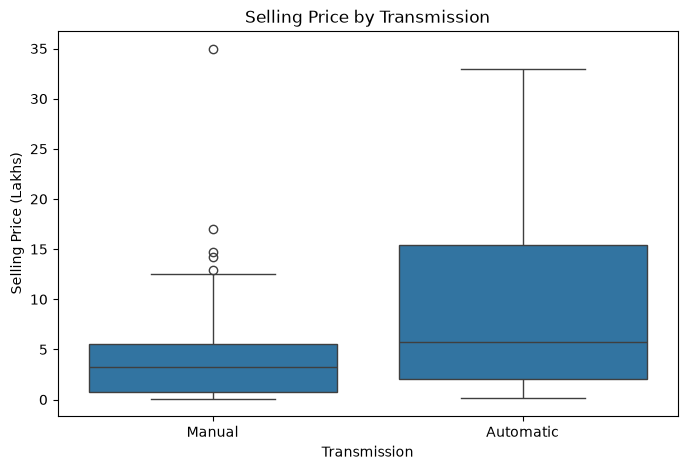

In [18]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Transmission", y="Selling_Price")
plt.title("Selling Price by Transmission")
plt.xlabel("Transmission")
plt.ylabel("Selling Price (Lakhs)")
plt.show()

In [19]:
df["Car_Age"] = 2018 - df["Year"]

df[["Year", "Car_Age"]].head()

,Year,Car_Age
0,2014,4
1,2013,5
2,2017,1
3,2011,7
4,2014,4


In [20]:
X = df[
    [
        "Car_Age",
        "Present_Price",
        "Kms_Driven",
        "Fuel_Type",
        "Seller_Type",
        "Transmission",
        "Owner"
    ]
]

y = df["Selling_Price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (299, 7)
Target shape: (299,)


In [21]:
X = pd.get_dummies(
    X,
    columns=["Fuel_Type", "Seller_Type", "Transmission"],
    drop_first=True
)

X.head()

,Car_Age,Present_Price,Kms_Driven,Owner,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual
0,4,5.59,27000,0,False,True,False,True
1,5,9.54,43000,0,True,False,False,True
2,1,9.85,6900,0,False,True,False,True
3,7,4.15,5200,0,False,True,False,True
4,4,6.87,42450,0,True,False,False,True


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (239, 8)
Testing features: (60, 8)
Training target: (239,)
Testing target: (60,)


In [23]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [24]:
y_pred_linear = linear_model.predict(X_test)

print("Predictions generated successfully!")
print("First 10 predicted prices:")
print(y_pred_linear[:10])

Predictions generated successfully!
First 10 predicted prices:
[ 7.50192151  7.79152142  1.36644388  7.00941894 11.16328988  4.53410247
  8.49246345  1.70078181  8.82421963 -0.96348801]


In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Performance")
print("------------------------------")
print("MAE :", mae_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)

Linear Regression Performance
------------------------------
MAE : 1.4728924140033466
RMSE: 2.524035054595451
R²  : 0.7528154215831603


In [26]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [27]:
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest predictions generated successfully!")
print("First 10 predicted prices:")
print(y_pred_rf[:10])

Random Forest predictions generated successfully!
First 10 predicted prices:
[ 9.5192  8.213   0.438   6.942  16.303   5.3035  7.0615  1.1745  7.8575
  0.2853]


In [28]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("-------------------------")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest Performance
-------------------------
MAE : 1.4042800000000013
RMSE: 3.29459812015568
R²  : 0.578851265325098


In [29]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [30]:
y_pred_gb = gradient_boosting_model.predict(X_test)

print("Gradient Boosting predictions generated successfully!")
print("First 10 predicted prices:")
print(y_pred_gb[:10])

Gradient Boosting predictions generated successfully!
First 10 predicted prices:
[ 9.38152648  8.68773412  0.48376155  7.13365675 15.02916938  4.7763802
  5.16347437  1.30776534  8.57187958  0.30271569]


In [31]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Performance")
print("-----------------------------")
print("MAE :", mae_gb)
print("RMSE:", rmse_gb)
print("R²  :", r2_gb)

Gradient Boosting Performance
-----------------------------
MAE : 1.1674842183588667
RMSE: 2.6161056109325576
R²  : 0.7344531511555503


In [32]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_linear,
        mae_rf,
        mae_gb
    ],
    "RMSE": [
        rmse_linear,
        rmse_rf,
        rmse_gb
    ],
    "R2 Score": [
        r2_linear,
        r2_rf,
        r2_gb
    ]
})

model_comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.472892,2.524035,0.752815
1,Random Forest,1.404280,3.294598,0.578851
2,Gradient Boosting,1.167484,2.616106,0.734453


In [34]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": gradient_boosting_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
1,Present_Price,0.899763
0,Car_Age,0.077083
2,Kms_Driven,0.008740
7,Transmission_Manual,0.006776
5,Fuel_Type_Petrol,0.003816
4,Fuel_Type_Diesel,0.003765
6,Seller_Type_Individual,0.000057
3,Owner,0.000000


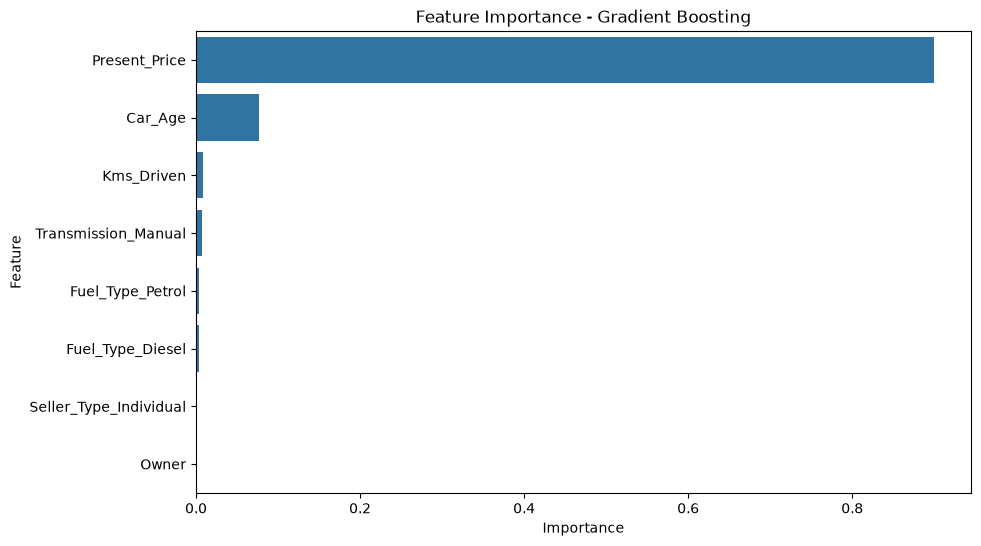

In [35]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

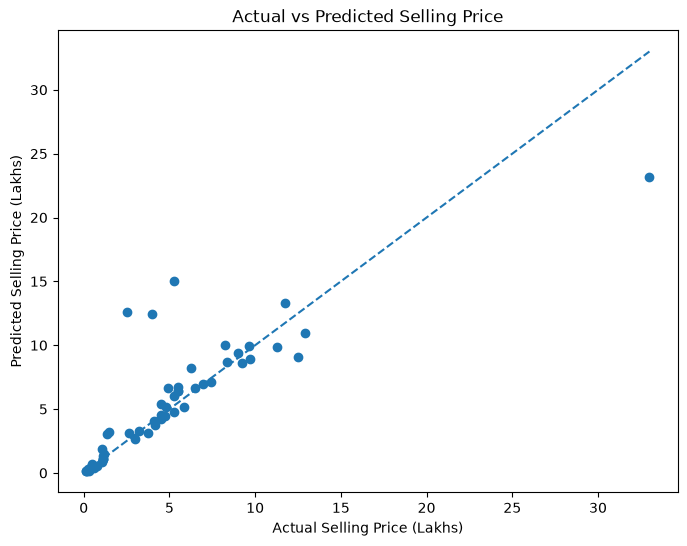

In [36]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_gb)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Selling Price")
plt.xlabel("Actual Selling Price (Lakhs)")
plt.ylabel("Predicted Selling Price (Lakhs)")

plt.show()

In [37]:
new_car = pd.DataFrame({
    "Car_Age": [5],
    "Present_Price": [8.5],
    "Kms_Driven": [30000],
    "Owner": [0],
    "Fuel_Type_Diesel": [False],
    "Fuel_Type_Petrol": [True],
    "Seller_Type_Individual": [False],
    "Transmission_Manual": [True]
})

predicted_price = gradient_boosting_model.predict(new_car)

print("Predicted Selling Price:", round(predicted_price[0], 2), "lakhs")

Predicted Selling Price: 5.24 lakhs


In [38]:
import joblib

joblib.dump(
    gradient_boosting_model,
    "car_selling_price_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [39]:
feature_columns = X.columns.tolist()

joblib.dump(
    feature_columns,
    "car_selling_price_features.pkl"
)

print("Feature columns saved successfully!")
print(feature_columns)

Feature columns saved successfully!
['Car_Age', 'Present_Price', 'Kms_Driven', 'Owner', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Seller_Type_Individual', 'Transmission_Manual']


In [40]:
loaded_model = joblib.load("car_selling_price_model.pkl")
loaded_features = joblib.load("car_selling_price_features.pkl")

loaded_prediction = loaded_model.predict(new_car[loaded_features])

print("Saved model loaded successfully!")
print("Predicted Selling Price:", round(loaded_prediction[0], 2), "lakhs")

Saved model loaded successfully!
Predicted Selling Price: 5.24 lakhs


In [42]:
final_results = model_comparison.copy()

final_results["MAE"] = final_results["MAE"].round(3)
final_results["RMSE"] = final_results["RMSE"].round(3)

r2_column = [col for col in final_results.columns if "R" in col and "2" in col or "²" in col][0]

final_results[r2_column] = final_results[r2_column].round(3)

final_results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.473,2.524,0.753
1,Random Forest,1.404,3.295,0.579
2,Gradient Boosting,1.167,2.616,0.734


In [43]:
import os

print("Model file exists:", os.path.exists("car_selling_price_model.pkl"))
print("Feature file exists:", os.path.exists("car_selling_price_features.pkl"))

Model file exists: True
Feature file exists: True


In [44]:
def predict_car_price(
    car_age,
    present_price,
    kms_driven,
    owner,
    fuel_type,
    seller_type,
    transmission
):
    input_data = pd.DataFrame({
        "Car_Age": [car_age],
        "Present_Price": [present_price],
        "Kms_Driven": [kms_driven],
        "Owner": [owner],
        "Fuel_Type_Diesel": [fuel_type == "Diesel"],
        "Fuel_Type_Petrol": [fuel_type == "Petrol"],
        "Seller_Type_Individual": [seller_type == "Individual"],
        "Transmission_Manual": [transmission == "Manual"]
    })

    input_data = input_data[feature_columns]

    prediction = loaded_model.predict(input_data)

    return prediction[0]


print("Prediction function created successfully!")

Prediction function created successfully!


In [45]:
test_prediction = predict_car_price(
    car_age=5,
    present_price=8.5,
    kms_driven=30000,
    owner=0,
    fuel_type="Petrol",
    seller_type="Dealer",
    transmission="Manual"
)

print("Predicted Selling Price:", round(test_prediction, 2), "lakhs")

Predicted Selling Price: 5.24 lakhs
